# EN3160 Assignment 2: Fitting and Alignment

**Name:** Anthony C.S.B.  
**Index No:** 230045X  
**GitHub:** https://github.com/BashithaAnthony/EN3160-Assignment-2-on-Fitting-and-Alignment

In [2]:
import os, glob
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
from scipy.optimize import minimize

%matplotlib inline

## Question 1: Blob detection (LoG and scale-space extrema)

**Method**
1. Load the image (reduced by 4) and convert to grayscale in [0, 1].
2. For each σ, build a scale-normalized LoG kernel (made zero-sum) and filter the image.
3. Square the response, so bright and dark blobs are treated equally.
4. Stack all responses into a 3D scale space (y, x, σ). Keep the points that are maximum in their 3×3×3 neighbourhood.
5. Reject weak points with a threshold. Then remove overlapping circles (keep the strongest).
6. Draw a circle of radius r = √2·σ at each blob.

**Decisions**
- **σ range:** 1.0 to 10.0, step 0.5 (19 values). Chosen after several runs. Smaller σ picks up petal noise. Larger σ picks up big areas such as sky and field, not flowers.
- **Threshold:** 0.5 × (maximum squared response). It was tuned so that only flower heads remain.
- **Overlap removal:** one flower gives peaks at several nearby scales. So a weaker blob is dropped if its centre is inside a stronger circle.

In [3]:
im = cv.imread('images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise FileNotFoundError("Image not found. Check the 'images' folder.")
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float64) / 255.0

sigmas = np.arange(1.0, 10.0 + 0.5, 0.5)
print("Sigma values used:", sigmas)
print(f"Range: {sigmas[0]} to {sigmas[-1]} ({len(sigmas)} values)")

# 3D scale space of squared, scale-normalized LoG responses
scale_space = []
for sigma in sigmas:
    hw = int(np.ceil(4 * sigma))
    X, Y = np.meshgrid(np.arange(-hw, hw + 1), np.arange(-hw, hw + 1))
    k = -1 / (2 * np.pi * sigma**2) * ((X**2 + Y**2) / sigma**2 - 2) * np.exp(-(X**2 + Y**2) / (2 * sigma**2))
    k -= k.mean()                                   # zero-sum kernel
    scale_space.append(cv.filter2D(gray, cv.CV_64F, k) ** 2)
scale_space = np.stack(scale_space, axis=-1)        # (H, W, num_sigmas)

# 3D non-maximum suppression + threshold
local_max = scale_space == ndimage.maximum_filter(scale_space, size=3)
threshold = 0.5 * scale_space.max()
ys, xs, ss = np.where(local_max & (scale_space > threshold))

# Overlap pruning: strongest first, drop a blob whose centre is inside a kept circle
blobs = sorted(zip(xs, ys, ss), key=lambda b: -scale_space[b[1], b[0], b[2]])
kept = []
for x, y, s in blobs:
    r = sigmas[s] * np.sqrt(2)
    if all(np.hypot(x - kx, y - ky) > max(r, sigmas[ks] * np.sqrt(2)) for kx, ky, ks in kept):
        kept.append((x, y, s))
print("Blobs before pruning:", len(blobs), " after pruning:", len(kept))

Sigma values used: [ 1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5  7.   7.5
  8.   8.5  9.   9.5 10. ]
Range: 1.0 to 10.0 (19 values)
Blobs before pruning: 82  after pruning: 81


Blob count per sigma:
  sigma =  1.0 -> 20
  sigma =  1.5 -> 14
  sigma =  2.0 -> 12
  sigma =  2.5 -> 8
  sigma =  3.0 -> 6
  sigma =  3.5 -> 5
  sigma =  4.0 -> 4
  sigma =  4.5 -> 6
  sigma =  5.0 -> 0
  sigma =  5.5 -> 2
  sigma =  6.0 -> 2
  sigma =  6.5 -> 0
  sigma =  7.0 -> 1
  sigma =  7.5 -> 1
  sigma =  8.0 -> 0
  sigma =  8.5 -> 0
  sigma =  9.0 -> 0
  sigma =  9.5 -> 0
  sigma = 10.0 -> 0

Largest radius: 11 px
  centre (x, y) = (0, 275), radius = 11 px, sigma = 7.5


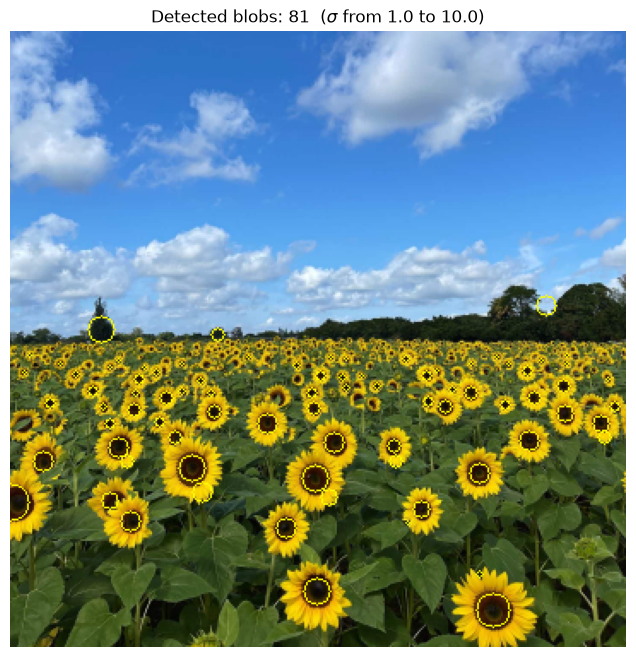

In [4]:
out = im.copy()
for x, y, s in kept:
    cv.circle(out, (int(x), int(y)), int(round(sigmas[s] * np.sqrt(2))), (0, 255, 255), 1)

# Report: blob count per sigma and largest circles
counts = np.bincount([s for _, _, s in kept], minlength=len(sigmas))
print("Blob count per sigma:")
for sg, c in zip(sigmas, counts):
    print(f"  sigma = {sg:4.1f} -> {c}")

radii = [int(round(sigmas[s] * np.sqrt(2))) for _, _, s in kept]
rmax = max(radii)
print(f"\nLargest radius: {rmax} px")
for (x, y, s), r in zip(kept, radii):
    if r == rmax:
        print(f"  centre (x, y) = ({x}, {y}), radius = {r} px, sigma = {sigmas[s]}")

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB))
plt.title(rf"Detected blobs: {len(kept)}  ($\sigma$ from {sigmas[0]} to {sigmas[-1]})")
plt.axis('off'); plt.show()

**Results and discussion**
- **σ range used:** 1.0 to 10.0 (step 0.5, 19 values). The radius range is about 1.4 to 14 px.
- **Blobs found:** 82 before pruning, **81 after pruning**.
- **Largest circle:** radius 11 px at centre (x, y) = (0, 275), σ = 7.5. This circle is **not a sunflower**. Its centre is on the left image border, in the sky region, so the blob is cut by the border.
- Most circles are on flower heads. Small σ (1.0 to 2.5) gives 54 of the 81 circles. These are the small, far flowers. Medium σ (3.0 to 4.5) gives 21 circles, for the closer flowers. Only 6 circles have σ ≥ 5.
- For the near flowers, the circle sits on the dark centre disc and not on the full flower head. The LoG responds most strongly to the dark centre, which is the clearest blob.
- A few false circles are in the sky and tree area (for example near the tree on the left). The threshold removes most weak responses, but a dark tree against a bright sky still gives a strong blob.
- A lower threshold finds more flowers but also adds more false circles. A higher threshold gives fewer false circles but misses more flowers.
- **Possible improvement:** ignore blobs whose circle crosses the image border, and search only the field region (below the horizon). This was not applied here.

## Question 2: RANSAC line and circle fitting

**Data:** 50 noisy circle points (centre (2, 3), r = 10) and 50 noisy line points (y = −x + 2). Seed is fixed for repeatable results.

In [5]:
np.random.seed(42)
N = 100; half_n = N // 2
r_gt, x0_gt, y0_gt = 10, 2, 3
t = np.random.uniform(0, 2 * np.pi, half_n)
n = (r_gt / 16) * np.random.randn(half_n)
X_circ = np.column_stack((x0_gt + (r_gt + n) * np.cos(t), y0_gt + (r_gt + n) * np.sin(t)))

m_gt, b_gt = -1, 2
x_line = np.linspace(-12, 12, half_n)
y_line = m_gt * x_line + b_gt + 1.0 * np.random.randn(half_n)
X_line = np.column_stack((x_line, y_line))
X = np.vstack((X_circ, X_line))          # first 50 rows: circle, last 50 rows: line

### (a) Line fitting with RANSAC

- **Model:** line `a x + b y = d` with unit normal `[a, b]`.
- **Sample:** 2 points. The normal is the perpendicular of the direction vector, divided by its length, so ‖[a, b]‖ = 1.
- **Error:** normal distance `|a x + b y − d|`.
- **Error threshold = 1.5.** The line noise has σ = 1 in y, so the normal distance has σ ≈ 0.7. A threshold of 1.5 is about 2σ, which keeps most true line points.
- **Minimum consensus = 40 points.** The line has 50 points, so about 80% are needed.
- **Iterations = 1000.** This is much larger than needed (checked below with N = log(1−p) / log(1−w^s)).
- **Final estimate:** total least squares on the inliers. `[a, b]` is the eigenvector of UᵀU with the smallest eigenvalue, so it has unit length.

In [6]:
def line_from_two(p1, p2):
    v = p2 - p1
    a, b = np.array([-v[1], v[0]]) / np.linalg.norm(v)      # unit normal
    return a, b, a * p1[0] + b * p1[1]

def fit_line_ransac(pts, iters=1000, thresh=1.5, min_inliers=40):
    best_idx, best_sample, best_model = [], None, None
    for _ in range(iters):
        i = np.random.choice(len(pts), 2, replace=False)
        p1, p2 = pts[i]
        if np.allclose(p1, p2): continue
        a, b, d = line_from_two(p1, p2)
        idx = np.where(np.abs(a * pts[:, 0] + b * pts[:, 1] - d) < thresh)[0]
        if len(idx) >= min_inliers and len(idx) > len(best_idx):
            best_idx, best_sample, best_model = idx, pts[i], (a, b, d)
    if best_sample is None:
        raise RuntimeError("No line model reached the minimum consensus")
    q = pts[best_idx]; mean = q.mean(axis=0); U = q - mean
    _, vecs = np.linalg.eigh(U.T @ U)                       # eigenvalues in ascending order
    a, b = vecs[:, 0]                                       # smallest eigenvalue -> normal
    return (a, b, a * mean[0] + b * mean[1]), best_idx, best_sample, best_model

def n_iter(w, s, p=0.99):                                   # iterations needed for confidence p
    return int(np.ceil(np.log(1 - p) / np.log(1 - w**s)))

line_p, line_idx, line_sample, line_sample_model = fit_line_ransac(X)
a, b, d = line_p
print(f"Best-fit line: a={a:.3f}, b={b:.3f}, d={d:.3f}  (norm = {np.hypot(a, b):.3f})")
print(f"Slope = {-a/b:.3f}, intercept = {d/b:.3f}   (ground truth: -1, 2)")
print(f"Line inliers: {len(line_idx)}  ({np.sum(line_idx >= 50)} from line, {np.sum(line_idx < 50)} from circle)")
print("Iterations needed (p = 0.99):", n_iter(len(line_idx) / len(X), 2))

Best-fit line: a=-0.704, b=-0.710, d=-1.316  (norm = 1.000)
Slope = -0.992, intercept = 1.854   (ground truth: -1, 2)
Line inliers: 53  (49 from line, 4 from circle)
Iterations needed (p = 0.99): 14


### (b) Circle fitting on the remaining points

- The line inliers are removed. The remaining points are used for the circle.
- **Sample:** 3 points. The circle through them is found from the perpendicular bisector equations.
- **Error:** radial error `| ‖p − c‖ − r |`.
- **Error threshold = 1.5.** The radial noise has σ = 10/16 = 0.625, so 1.5 is about 2.4σ.
- **Minimum consensus = 35 points.** The circle has 50 points. Some of them were already removed with the line, so a lower limit is used.
- **Final estimate:** `scipy.optimize.minimize` on the sum of squared radial errors of the inliers, starting from the sample circle.

In [7]:
def circle_from_three(p1, p2, p3):
    A = 2 * np.array([[p2[0] - p1[0], p2[1] - p1[1]], [p3[0] - p1[0], p3[1] - p1[1]]])
    if abs(np.linalg.det(A)) < 1e-6: return None            # points almost in a line
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    cx, cy = np.linalg.solve(A, rhs)
    return cx, cy, np.hypot(p1[0] - cx, p1[1] - cy)

def fit_circle_ransac(pts, iters=1000, thresh=1.5, min_inliers=35):
    best_idx, best_sample, best_model = [], None, None
    for _ in range(iters):
        i = np.random.choice(len(pts), 3, replace=False)
        model = circle_from_three(*pts[i])
        if model is None: continue
        cx, cy, r = model
        idx = np.where(np.abs(np.hypot(pts[:, 0] - cx, pts[:, 1] - cy) - r) < thresh)[0]
        if len(idx) >= min_inliers and len(idx) > len(best_idx):
            best_idx, best_sample, best_model = idx, pts[i], model
    if best_sample is None:
        raise RuntimeError("No circle model reached the minimum consensus")
    q = pts[best_idx]
    loss = lambda p: np.sum((np.hypot(q[:, 0] - p[0], q[:, 1] - p[1]) - p[2]) ** 2)
    res = minimize(loss, best_model)
    return tuple(res.x), best_idx, best_sample, best_model

remnant_idx = np.delete(np.arange(len(X)), line_idx)
X_rem = X[remnant_idx]
circ_p, circ_idx, circ_sample, circ_sample_model = fit_circle_ransac(X_rem)
cx, cy, cr = circ_p
print(f"Remaining points: {len(X_rem)}")
print(f"Best-fit circle: centre=({cx:.3f}, {cy:.3f}), r={cr:.3f}   (ground truth: (2, 3), 10)")
print(f"Circle inliers: {len(circ_idx)}")
print("Iterations needed (p = 0.99):", n_iter(len(circ_idx) / len(X_rem), 3))

Remaining points: 47
Best-fit circle: centre=(1.956, 3.042), r=10.010   (ground truth: (2, 3), 10)
Circle inliers: 46
Iterations needed (p = 0.99): 2


### (c) Result plot
The plot shows all points, the sample-based line and circle, the two samples, the best-fit line and circle, both sets of inliers, and the ground truth.

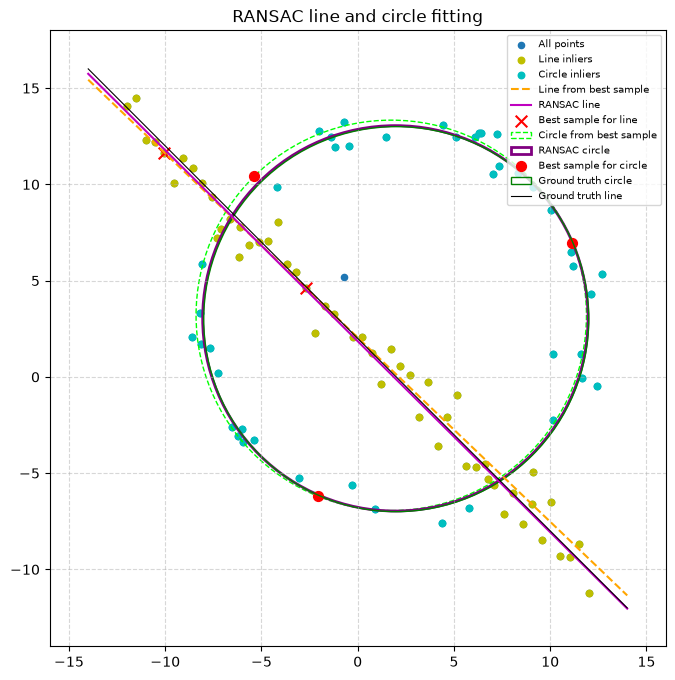

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(X[:, 0], X[:, 1], color='tab:blue', s=20, label='All points')
ax.scatter(*X[line_idx].T, color='y', s=22, label='Line inliers')
ax.scatter(*X_rem[circ_idx].T, color='c', s=22, label='Circle inliers')

xs_ = np.array([-14, 14.0])
def draw_line(a, b, d, **kw): ax.plot(xs_, (d - a * xs_) / b, **kw)
draw_line(*line_sample_model, color='orange', ls='--', label='Line from best sample')
draw_line(a, b, d, color='m', label='RANSAC line')
ax.scatter(*line_sample.T, color='r', marker='x', s=70, label='Best sample for line')

ax.add_patch(plt.Circle(circ_sample_model[:2], circ_sample_model[2], fill=False, color='lime', ls='--', label='Circle from best sample'))
ax.add_patch(plt.Circle((cx, cy), cr, fill=False, color='purple', lw=2, label='RANSAC circle'))
ax.scatter(*circ_sample.T, color='r', s=50, label='Best sample for circle')

ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, fill=False, color='g', label='Ground truth circle'))
ax.plot(xs_, m_gt * xs_ + b_gt, color='k', lw=0.8, label='Ground truth line')
ax.set_xlim(-16, 16); ax.set_ylim(-14, 18); ax.set_aspect('equal'); ax.grid(ls='--', alpha=0.5)
ax.legend(fontsize=7, loc='upper right'); ax.set_title('RANSAC line and circle fitting')
plt.show()

**Discussion**
- The estimated line and circle are very close to the ground truth.

| | Estimated | Ground truth |
|---|---|---|
| Line slope, intercept | −0.992, 1.854 | −1, 2 |
| Circle centre | (1.956, 3.042) | (2, 3) |
| Circle radius | 10.010 | 10 |

- The line has 53 inliers: 49 true line points and 4 circle points that lie near the line. The circle has 46 inliers out of 47 remaining points.
- The 4 circle points in the line consensus are the reason the circle needs a lower minimum consensus (35).
- The iterations needed for 99% confidence are only 14 (line) and 2 (circle). The 1000 iterations used are more than enough.
- The final TLS and `minimize` steps improve the sample-based models. They use all the inliers and not only 2 or 3 points. The sample-based circle (dashed green) is slightly off, and the optimized circle matches the ground truth.

### (d) What happens if the circle is fitted first?
The code below fits the circle on all points first, then the line on the remaining points.

Circle first: centre=(2.161, 3.010), r=9.829, inliers=62 (line points taken: 12)
Line after:   slope=-1.005, intercept=1.931, inliers=37


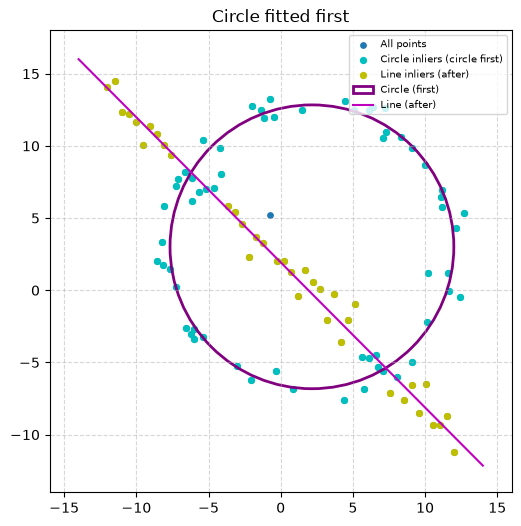

In [9]:
cp2, ci2, cs2, cm2 = fit_circle_ransac(X)
rem2 = np.delete(np.arange(len(X)), ci2)
lp2, li2, ls2, lm2 = fit_line_ransac(X[rem2], min_inliers=30)
print(f"Circle first: centre=({cp2[0]:.3f}, {cp2[1]:.3f}), r={cp2[2]:.3f}, inliers={len(ci2)} (line points taken: {np.sum(ci2 >= 50)})")
print(f"Line after:   slope={-lp2[0]/lp2[1]:.3f}, intercept={lp2[2]/lp2[1]:.3f}, inliers={len(li2)}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(X[:, 0], X[:, 1], color='tab:blue', s=15, label='All points')
ax.scatter(*X[ci2].T, color='c', s=18, label='Circle inliers (circle first)')
ax.scatter(*X[rem2][li2].T, color='y', s=18, label='Line inliers (after)')
ax.add_patch(plt.Circle(cp2[:2], cp2[2], fill=False, color='purple', lw=2, label='Circle (first)'))
ax.plot(xs_, (lp2[2] - lp2[0] * xs_) / lp2[1], color='m', label='Line (after)')
ax.set_xlim(-16, 16); ax.set_ylim(-14, 18); ax.set_aspect('equal'); ax.grid(ls='--', alpha=0.5)
ax.legend(fontsize=7, loc='upper right'); ax.set_title('Circle fitted first')
plt.show()

**Answer**
- A line can be seen as a circle with a very large radius. So a circle model can also fit straight line points.
- In our run, the circle-first fit took **62 inliers, and 12 of them were line points**. After removing them, the line had only **37 inliers**, compared to 49 true line points when the line is fitted first.
- The circle was also pulled towards the line points:

| | Line first | Circle first | Ground truth |
|---|---|---|---|
| Circle centre | (1.956, 3.042) | (2.161, 3.010) | (2, 3) |
| Circle radius | 10.010 | 9.829 | 10 |
| Line intercept | 1.854 | 1.931 | 2 |

- The centre error is 0.06 for line first and 0.16 for circle first. The radius error is 0.01 and 0.17.
- The result was still acceptable here, because the circle has more points than the line. But it is less reliable. A sample of 3 nearly collinear points can give a huge circle that collects many line points.
- So fitting the line first is safer. A line cannot fit circle points well, but a circle can fit line points.

## Question 3: Superimposing an image using a homography

**Method**
1. Click 4 corners on a flat surface in the target image (top-left, top-right, bottom-right, bottom-left).
2. Compute the homography **H** that maps the 4 corners of the source image to the 4 clicked points.
3. Warp the source image with **H** and blend it into the target inside the clicked quadrilateral (70% source, 30% target, like Figure 2).

**Rationale for the image pairs**
- **Wadham College + UK flag:** same as the handout example, so the result can be checked against Figure 2. The wall is a large, flat surface with clear corners.
- **Blank billboard + Coca-Cola banner:** a billboard is a large flat rectangle with clear corners, so a homography fits well. A well-known logo makes any distortion easy to see.

*The clicking cell uses the `qt` backend (a pop-up window). `plt.ginput` needs `timeout=0`, otherwise it stops after 30 s. The result is shown inline in the next cell.*

In [10]:
%matplotlib qt
pairs = [('images/wadham.jpg', 'images/flag.png', 'aligned_result_1.jpg'),
         ('images/banner_placeholder.jpg', 'images/cocacola_banner.jpg', 'aligned_result_2.jpg')]

clicked = {}
for tgt, src, out in pairs:
    img = cv.cvtColor(cv.imread(tgt), cv.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 8)); plt.imshow(img)
    plt.title("Click: 1 Top-Left, 2 Top-Right, 3 Bottom-Right, 4 Bottom-Left")
    clicked[out] = np.array(plt.ginput(4, timeout=0))
    plt.close()
    print(out, clicked[out].round(1).tolist())      # copy these to re-run without clicking

aligned_result_1.jpg [[146.7, 207.0], [444.9, 272.8], [447.9, 518.1], [131.7, 521.1]]
aligned_result_2.jpg [[120.3, 21.8], [557.0, 165.0], [577.0, 365.8], [127.3, 279.5]]


Homography for aligned_result_1.jpg:
[[ 2.203000e-01 -2.380000e-02  1.467000e+02]
 [ 7.410000e-02  2.953000e-01  2.069597e+02]
 [ 1.000000e-04 -1.000000e-04  1.000000e+00]]

Homography for aligned_result_2.jpg:
[[ 8.240000e-01  4.900000e-03  1.202779e+02]
 [ 2.630000e-01  7.128000e-01  2.180650e+01]
 [ 4.000000e-04 -1.000000e-04  1.000000e+00]]



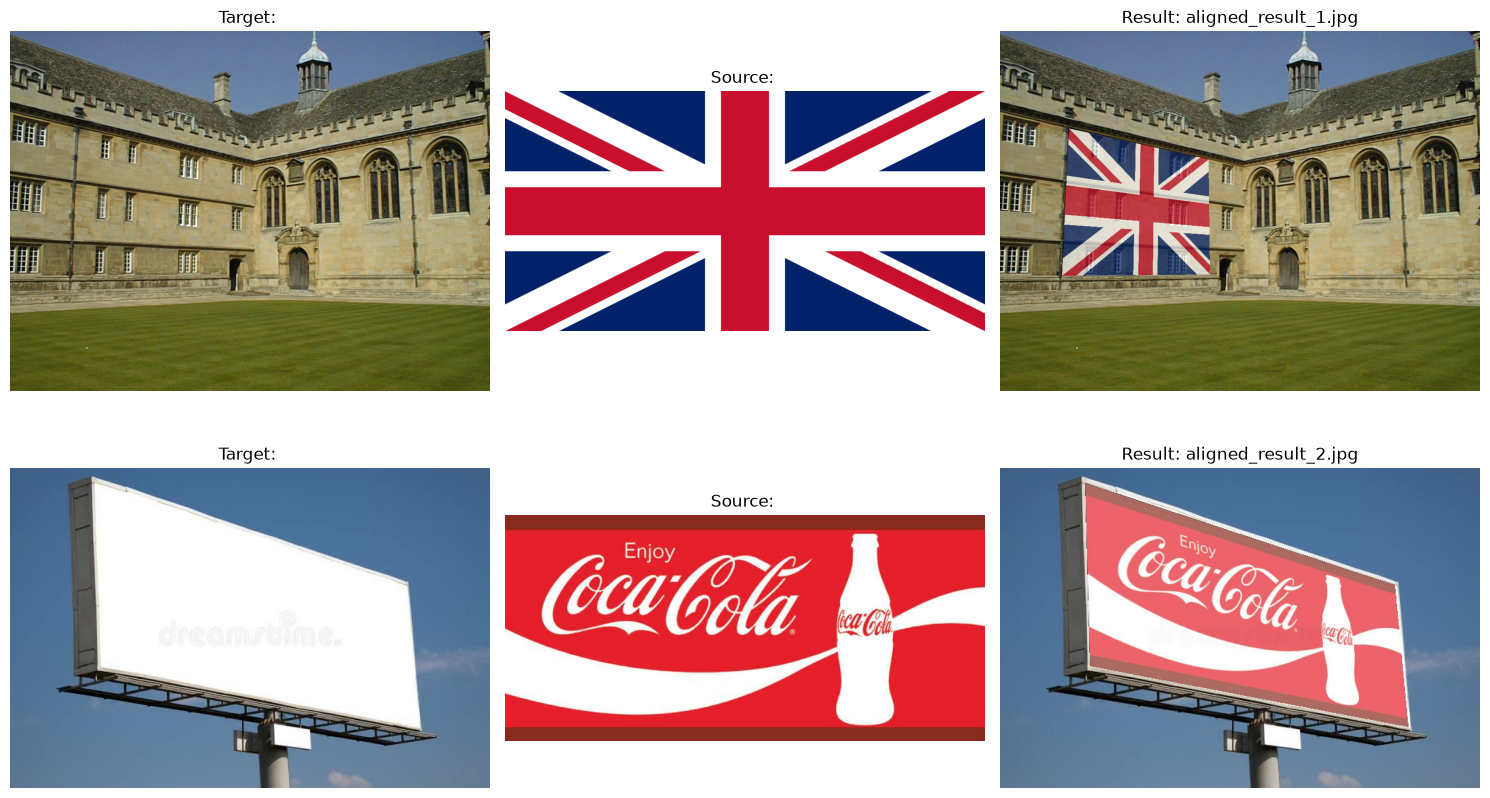

In [11]:
%matplotlib inline
def superimpose(target_path, source_path, dst_pts, out_path, alpha=0.7):
    tgt = cv.cvtColor(cv.imread(target_path), cv.COLOR_BGR2RGB)
    src = cv.cvtColor(cv.imread(source_path), cv.COLOR_BGR2RGB)
    h, w = src.shape[:2]
    src_pts = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float32)
    dst_pts = np.asarray(dst_pts, dtype=np.float32)

    H, _ = cv.findHomography(src_pts, dst_pts)
    warped = cv.warpPerspective(src, H, (tgt.shape[1], tgt.shape[0]))

    mask = np.zeros(tgt.shape[:2], np.uint8)
    cv.fillConvexPoly(mask, dst_pts.astype(np.int32), 255)
    blend = cv.addWeighted(tgt, 1 - alpha, warped, alpha, 0)
    result = np.where(mask[..., None] > 0, blend, tgt)

    cv.imwrite(out_path, cv.cvtColor(result, cv.COLOR_RGB2BGR))
    return src, tgt, H, result

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, (tgt, src, out) in enumerate(pairs):
    s, t_, H, res = superimpose(tgt, src, clicked[out], out)
    print(f"Homography for {out}:\n{np.round(H, 4)}\n")
    for ax_, im_, title in zip(axes[row], [t_, s, res], ['Target', 'Source', 'Result']):
        ax_.imshow(im_); ax_.set_title(f"{title}: {os.path.basename(out) if title == 'Result' else ''}"); ax_.axis('off')
plt.tight_layout(); plt.show()

**Discussion**
- Both source images are placed on the chosen planes with the correct perspective. The flag follows the wall of the building, and the logo follows the billboard edges, which get smaller towards the right.
- With 70% opacity, the windows and brick texture of the wall are still visible through the flag. The faint watermark on the billboard is also visible. This looks natural, but the colours are a little washed out.
- A homography is exact only for a **flat surface**, so the corners must lie on one plane. A billboard and a wall are flat, so the result is good.
- The result depends on how accurately the corners are clicked. A small error in a corner changes the whole warp. Small gaps can be seen at the billboard edges because of this.

## Question 4: PCB alignment with SIFT and homography

**Method (for each PCB image)**
1. **(a)** Detect SIFT keypoints and descriptors in the template (`AECC1.jpg`) and in the PCB image.
2. **(b)** Match with `cv2.BFMatcher()` (L2 norm) and keep matches that pass Lowe's ratio test (0.8). Find the homography with RANSAC (reprojection threshold 5 px). Draw the RANSAC inlier matches.
3. **(c)** Warp the PCB image to the template. Compute the absolute difference. A mask removes the black border from the warp, so it is not counted as difference.
4. **(d)** Repeat for all images.

PCB images: ['AAAA1.jpg', 'ADAD1.jpg', 'AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg']


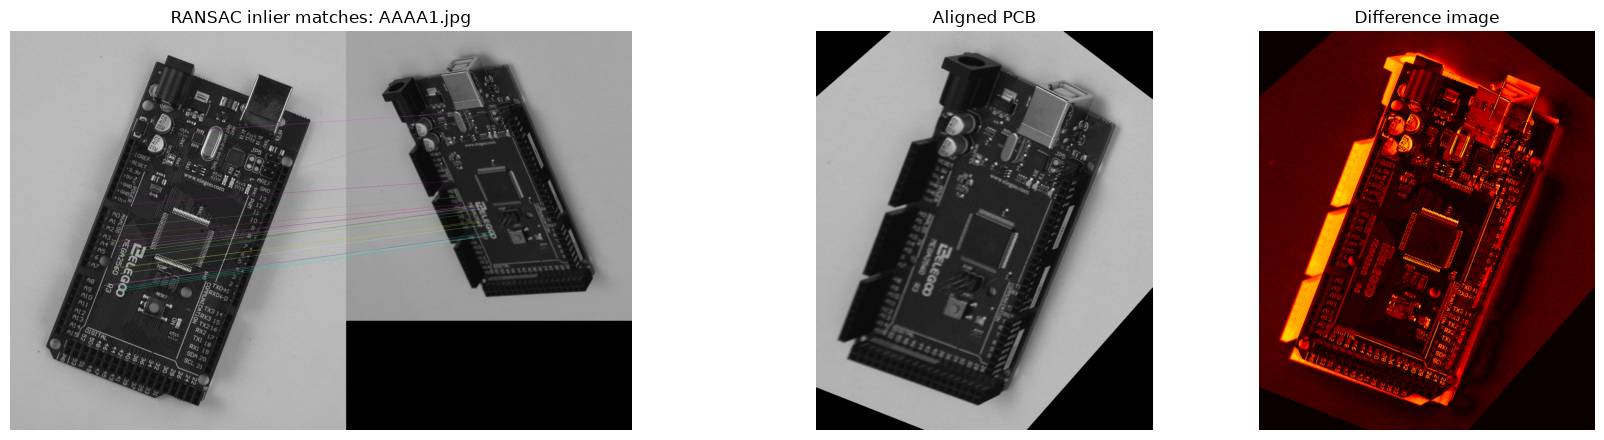

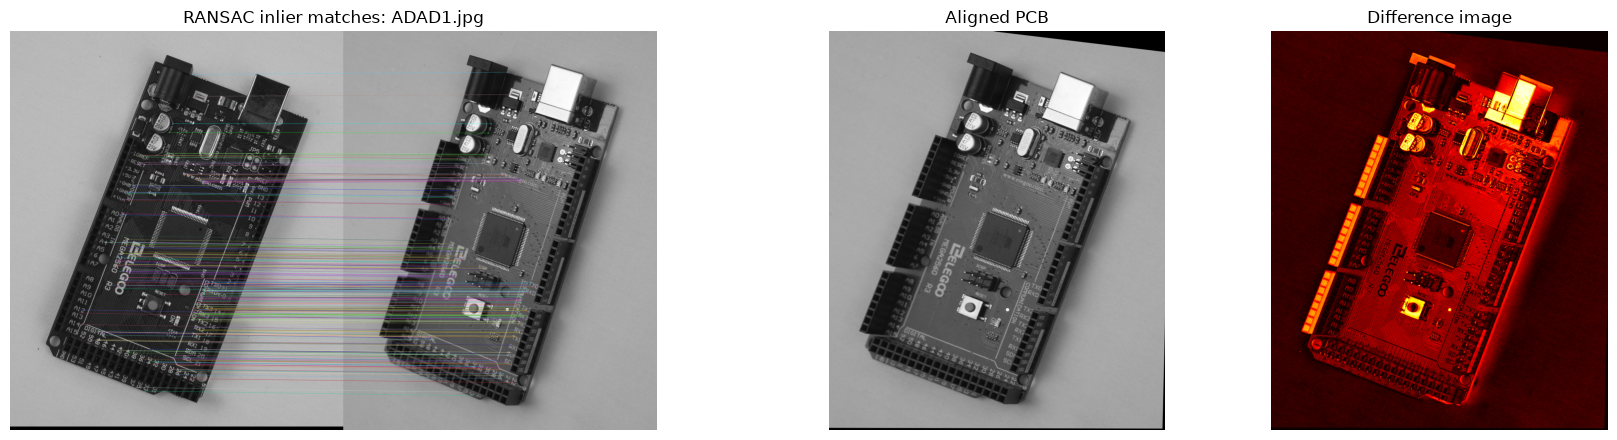

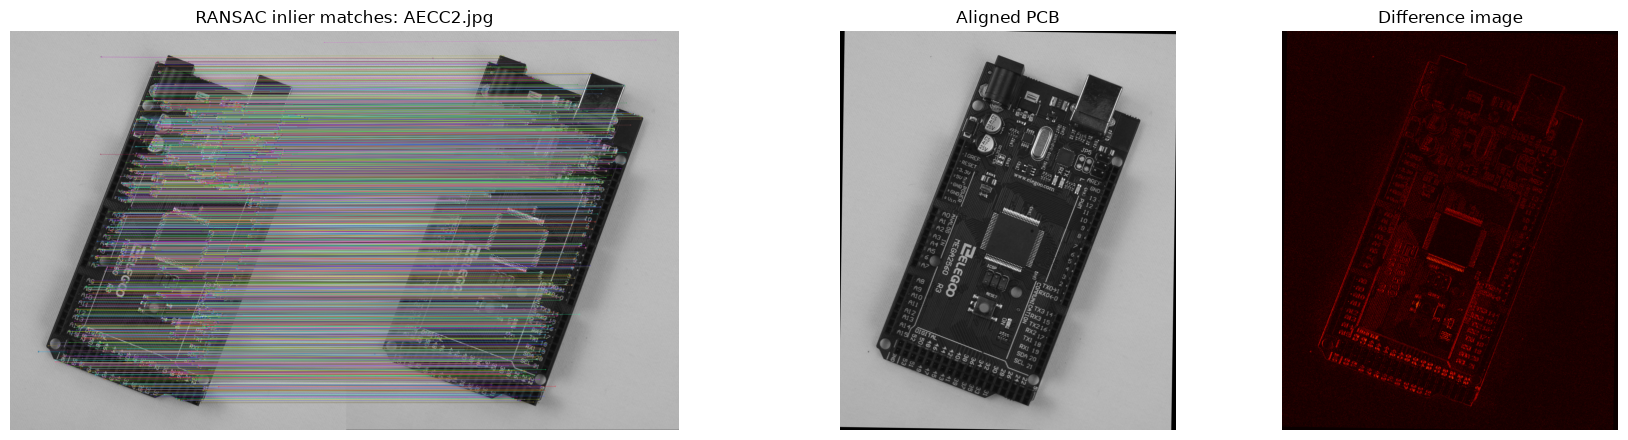

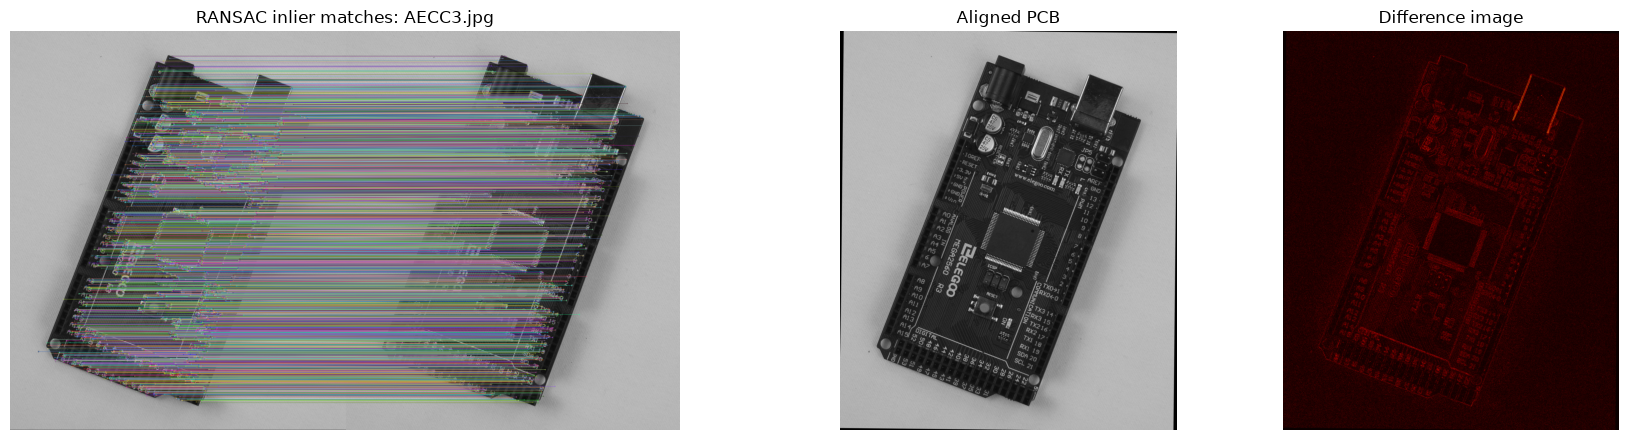

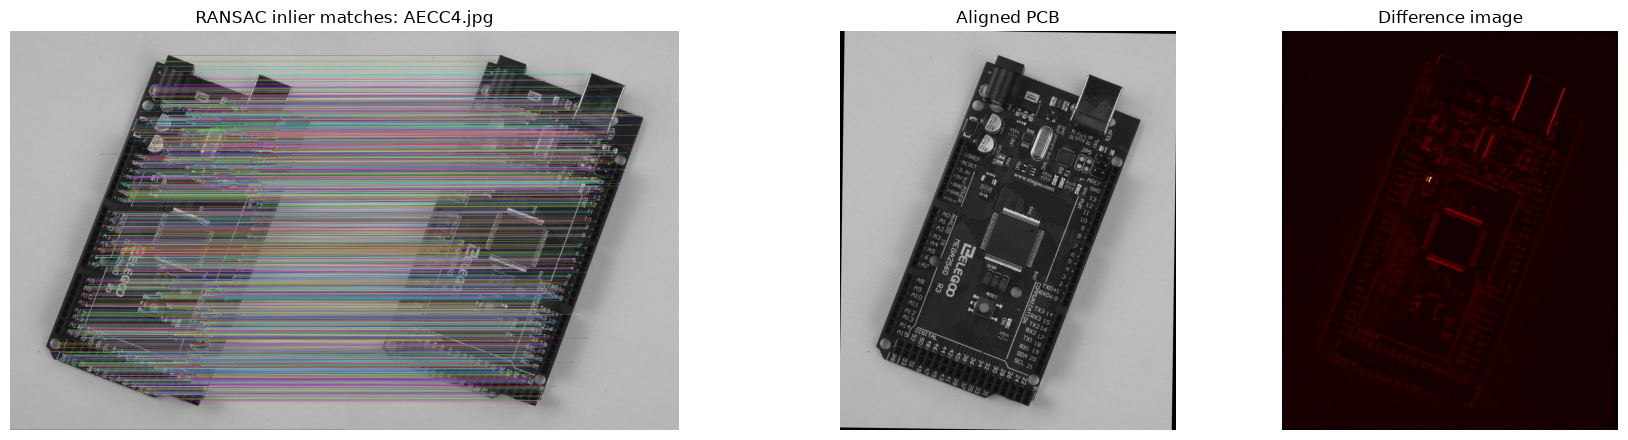

Image        Keypoints    Good  Inliers  Inlier %  Mean diff
AAAA1.jpg         2413     770       21      2.7%      28.18
ADAD1.jpg         8488    1098      267     24.3%      31.14
AECC2.jpg        12312    5278     4215     79.9%       3.01
AECC3.jpg        15197    6266     5266     84.0%       2.78
AECC4.jpg        11610    4668     3676     78.7%       3.58


In [12]:
template_path = 'images/pcb/AECC1.jpg'
pcb_paths = sorted(p for p in glob.glob('images/pcb/*.jpg') if os.path.basename(p) != 'AECC1.jpg')
print("PCB images:", [os.path.basename(p) for p in pcb_paths])

img_t = cv.imread(template_path, cv.IMREAD_GRAYSCALE)
sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(img_t, None)
bf = cv.BFMatcher()

def align_and_compare(path):
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)
    kp2, des2 = sift.detectAndCompute(img, None)
    good = [p[0] for p in bf.knnMatch(des1, des2, k=2) if len(p) == 2 and p[0].distance < 0.8 * p[1].distance]

    src = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)   # PCB image
    dst = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)   # template
    H, inl = cv.findHomography(src, dst, cv.RANSAC, 5.0)

    h, w = img_t.shape
    aligned = cv.warpPerspective(img, H, (w, h))
    valid = cv.warpPerspective(np.full_like(img, 255), H, (w, h))
    valid = cv.erode((valid > 254).astype(np.uint8), np.ones((5, 5), np.uint8))   # drop blurry border
    diff = cv.absdiff(img_t, aligned) * valid

    vis = cv.drawMatches(img_t, kp1, img, kp2, good, None, matchesMask=inl.ravel().tolist(),
                         flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    stats = dict(kp=len(kp2), good=len(good), inliers=int(inl.sum()), mean_diff=float(diff[valid > 0].mean()))
    return vis, aligned, diff, stats

results = {}
for p in pcb_paths:
    vis, aligned, diff, st = align_and_compare(p)
    results[p] = st
    fig = plt.figure(figsize=(18, 4.5))
    gs = fig.add_gridspec(1, 3, width_ratios=[2, 1, 1])
    ax = fig.add_subplot(gs[0]); ax.imshow(vis); ax.set_title(f"RANSAC inlier matches: {os.path.basename(p)}"); ax.axis('off')
    ax = fig.add_subplot(gs[1]); ax.imshow(aligned, cmap='gray'); ax.set_title('Aligned PCB'); ax.axis('off')
    ax = fig.add_subplot(gs[2]); ax.imshow(diff, cmap='hot'); ax.set_title('Difference image'); ax.axis('off')
    plt.tight_layout(); plt.show()

print(f"{'Image':<12}{'Keypoints':>10}{'Good':>8}{'Inliers':>9}{'Inlier %':>10}{'Mean diff':>11}")
for p, s in results.items():
    print(f"{os.path.basename(p):<12}{s['kp']:>10}{s['good']:>8}{s['inliers']:>9}{100*s['inliers']/s['good']:>9.1f}%{s['mean_diff']:>11.2f}")

**Discussion**

| Image | Keypoints | Good matches | Inliers | Inlier % | Mean diff |
|---|---|---|---|---|---|
| AAAA1 | 2413 | 770 | 21 | 2.7% | 28.18 |
| ADAD1 | 8488 | 1098 | 267 | 24.3% | 31.14 |
| AECC2 | 12312 | 5278 | 4215 | 79.9% | 3.01 |
| AECC3 | 15197 | 6266 | 5266 | 84.0% | 2.78 |
| AECC4 | 11610 | 4668 | 3676 | 78.7% | 3.58 |

- **AECC2, AECC3, AECC4 (same setup as the template):** Many inliers (about 79 to 84%) and a very small mean difference (2.8 to 3.6). The aligned boards overlap the template well. The difference images are almost black, with only thin lines on component edges.
- **ADAD1:** The geometric alignment looks correct, but the mean difference is high (31.14). This image is much brighter than the template (different lighting or exposure), so the difference is large over the whole board. So the mean difference does not show alignment quality only. Lighting changes also add to it.
- **AAAA1:** Alignment is poor. There are only 21 inliers (2.7%) and the board is shifted and stretched compared to the template, which gives bright bands on the board edges. This image has a large rotation, and it is dark and has low contrast. It gives only 2413 keypoints, so most of the 770 good matches are wrong.
- The inlier ratio is a good indicator of success. Images with a high inlier ratio are well aligned. The two with a low ratio are not.
- The warp mask is needed. Without it, the black border created by the warp would appear as a false difference.
- **Possible improvement:** match the brightness (for example, histogram equalization) before the difference. Also, a stricter ratio test can help for AAAA1.

### (e) Why do the USB Type B port, capacitors and reset button show high difference?
1. **They are not flat.** A homography is exact only for a plane. These parts stand high above the board. When the camera position changes, tall parts shift by a different amount than the board (parallax). So they do not line up after the warp.
2. **Shiny surfaces.** The metal USB shell and the capacitor tops reflect light. Their brightness changes with the viewing angle and the lighting. This is clearly seen in ADAD1, where the USB port is very bright.
3. **Shadows and lighting changes.** Tall parts cast shadows. The shadows move when the light or the camera moves.
4. **Small alignment errors.** These parts have strong edges and high contrast. An error of a pixel or two gives a large difference there.